In [1]:
import matplotlib.pyplot as plt
import pandas as pd


In [4]:
data_root = "../../tasks/lab2/dataset/lab2-01.xlsx"
data = pd.read_excel(data_root, header=None)

In [5]:
data.head(5)

,0,1
0,0.000000,1.000000
1,6.966738,9.136125
2,6.792361,-4.791980
3,5.849622,-5.671065
4,-9.331613,8.760587


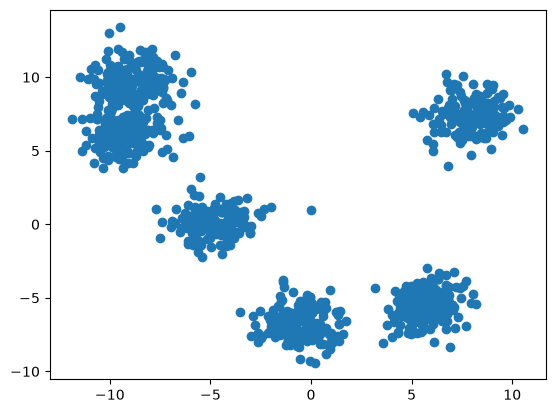

In [6]:
plt.scatter(data[0], data[1])

In [7]:
from sklearn.cluster import KMeans, DBSCAN

In [8]:
model_kmeans = KMeans()
model_kmeans.fit_predict(data)

array([7, 2, 3, ..., 2, 6, 2], shape=(1001,), dtype=int32)

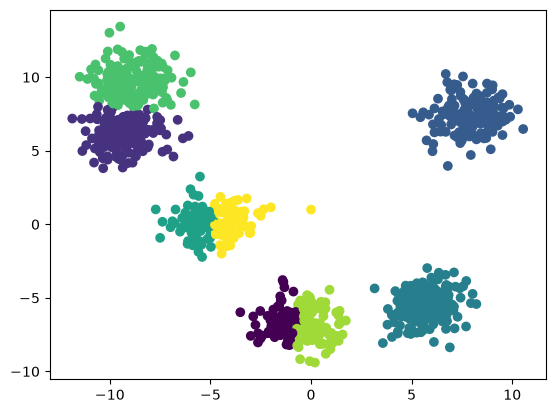

In [10]:
plt.scatter(data[0], data[1], c=model_kmeans.labels_)

Получившееся разбиение явно неудовлетворительно. Настроим параметры вручную

In [11]:
model_kmeans2 = KMeans(n_clusters=5)
model_kmeans2.fit_predict(data)

array([3, 2, 1, ..., 2, 4, 2], shape=(1001,), dtype=int32)

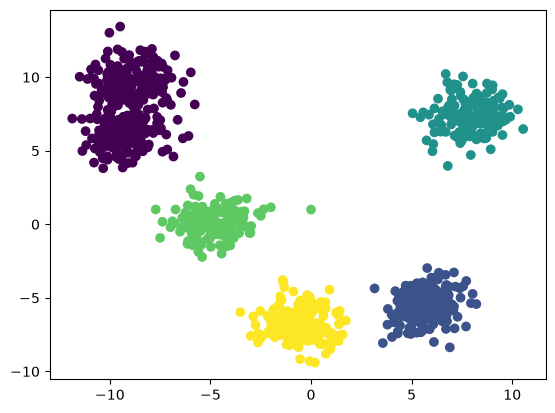

In [12]:
plt.scatter(data[0], data[1], c=model_kmeans2.labels_)

Так как данные представляют из себя выпуклые и довольно гладкие центроиды, алгоритм KMeans идеально показывает себя в таком кейсе

In [13]:
model_dbscan = DBSCAN()
model_dbscan.fit_predict(data)

array([-1,  0,  1, ...,  0,  4,  0], shape=(1001,))

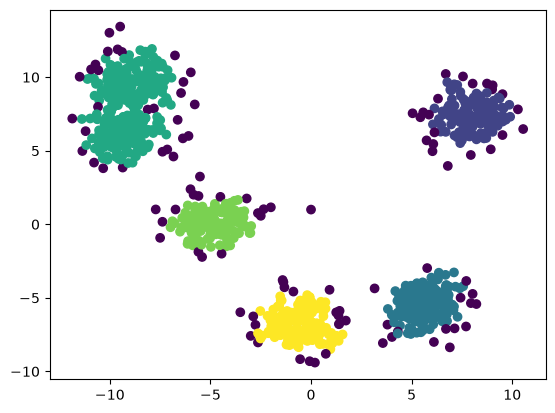

In [14]:
plt.scatter(data[0], data[1], c=model_dbscan.labels_)

При стандартных настройках параметров алгоритм отбросил слишком много хороших точек

In [17]:
model_dbscan2 = DBSCAN(min_samples=4, eps=1.7)
model_dbscan2.fit_predict(data)

array([-1,  0,  1, ...,  0,  4,  0], shape=(1001,))

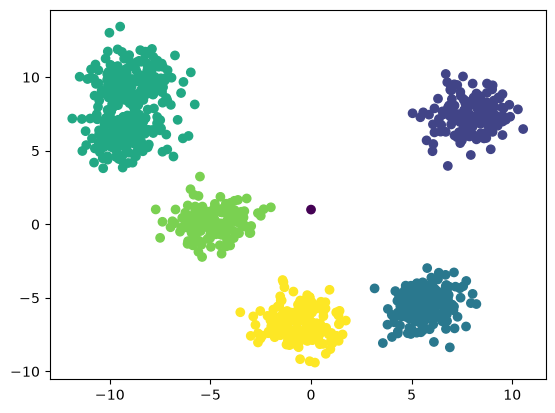

In [18]:
plt.scatter(data[0], data[1], c=model_dbscan2.labels_)

На этих данных разница в работе двух алгоритмов минимальна. Однако, ДБСКАН показывает свое преимущество на более сложно устроенных данных, такие как кривые или концентрические кольца